In [1]:
# %load run_py21cmfast.py
import numpy as np, os
import matplotlib.pyplot as plt
import tools21cm as t2c
from tqdm import tqdm
from scipy.stats import binned_statistic_dd

import astropy.units as u

2024-08-26 13:55:51.217699: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-08-26 13:55:51.567633: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-08-26 13:55:51.567761: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-08-26 13:55:51.620437: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-08-26 13:55:51.746248: I tensorflow/core/platform/cpu_feature_guar

In [2]:
#path_input = '/scratch/snx3000/mibianco/sdc3b/run_256Mpc_128_1e10/'
path_input = '/home/mbianco/Documents/PostDoc_EPFL/output/SERENEt/serenet_paper/jwst_prior/'
path_out = path_input

redshift = [7.916, 8.844, 9.868]
boxsize = 256 # cMpc

In [3]:
from astropy.cosmology import Planck18 as cosmo
import astropy.constants as cst

def r_mfp(z):
    return (cst.c/cosmo.H(z)).to('Mpc') * 0.1 * np.power((1+z)/4, -2.55)

def fake_simulator(pos, shape, z, res):
    cube = np.zeros(shape)
    xx, yy, zz = np.meshgrid(np.arange(shape[0]), np.arange(shape[1]), np.arange(shape[2]), sparse=True)
    
    # radius
    r  = int(round(r_mfp(z).value*(1+z)/res, 0)) # proper to comoving
    r2 = (xx-shape[0]/2)**2+(yy-shape[1]/2)**2+(zz-shape[2]/2)**2

    # Bubble 0
    xx0, yy0, zz0 = int(shape[0]/2), int(shape[1]/2), int(shape[2]/2)
    cube0 = np.zeros(shape)
    cube0[r2<=r**2] = 1
    cube0 = np.roll(np.roll(np.roll(cube0, -xx0, axis=0), -yy0, axis=1), -zz0, axis=2)

    # Bubble 1
    xx1, yy1, zz1 = pos[0], pos[1], pos[2]
    cube = cube+np.roll(np.roll(np.roll(cube0, xx1, axis=0), yy1, axis=1), zz1, axis=2)
    return cube


In [4]:
def fake_simulator2(pos, shape, z, res):
    radius  = int(round(r_mfp(z).value*(1+z)/res, 0)) # proper to comoving
    semisizes = (radius,) * 3
    grid = [slice(-x0, dim - x0) for x0, dim in zip(pos, shape)]
    pos = np.ogrid[grid]
    arr = np.zeros(shape, dtype=float)
    
    for x_i, semisize in zip(pos, semisizes):
        arr += (x_i / semisize) ** 2

    return arr <= 1.0

In [5]:
%%time
a = fake_simulator2([64,64,64], (128,128,128), 10, 2.0)

CPU times: user 4.35 ms, sys: 16.3 ms, total: 20.7 ms
Wall time: 18.7 ms


In [6]:
%%time
a = fake_simulator([64,64,64], (128,128,128), 10, 2.0)

CPU times: user 18.8 ms, sys: 24.1 ms, total: 43 ms
Wall time: 41.4 ms


# Make Bubble mask 

In [ ]:
for i_z in tqdm(range(len(redshift)):
    z = redshift[i_z]

    if not os.path.exists('%ssrcmask_z%.3f.npy' %(path_sources, z)):
        nion = np.load('%snion_z%.3f.npy' %(path_sources, z))
        h_pos = np.array(np.nonzero(nion)).T
        #print(np.count_nonzero(nion))

        cube = np.zeros_like(nion)
        for pos in h_pos:
            cube += fake_simulator2(pos=pos, shape=nion.shape, z=z, res=boxsize/nion.shape[0])
        np.save('%ssrcmask_z%.3f.npy' %(path_sources, z), cube)

 84%|████████▎ | 72/86 [2:39:02<2:34:58, 664.20s/it]

the same bubble mask for only the __i_cut__ largest sources

z = 7.916
8.257501940512956


100%|████████████████████████████████████| 10000/10000 [00:53<00:00, 187.13it/s]


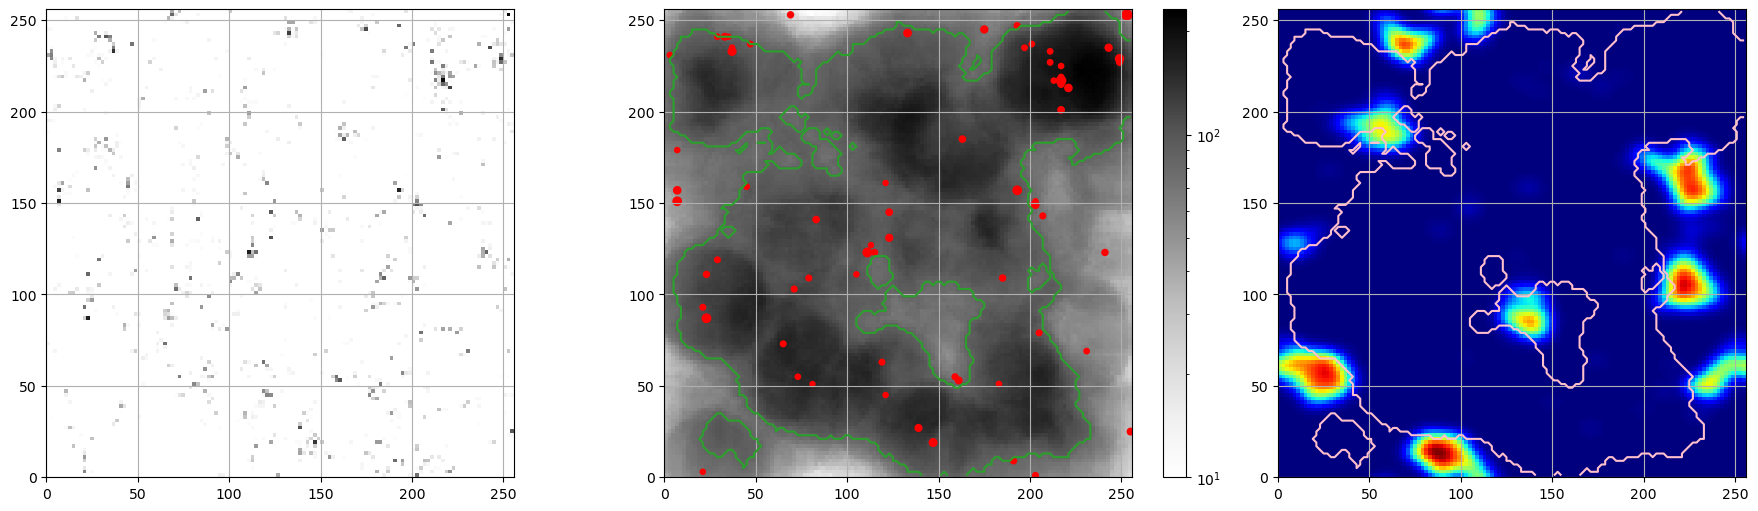

z = 8.844
15.121958596077365


100%|████████████████████████████████████| 10000/10000 [00:48<00:00, 207.55it/s]


<Figure size 640x480 with 0 Axes>

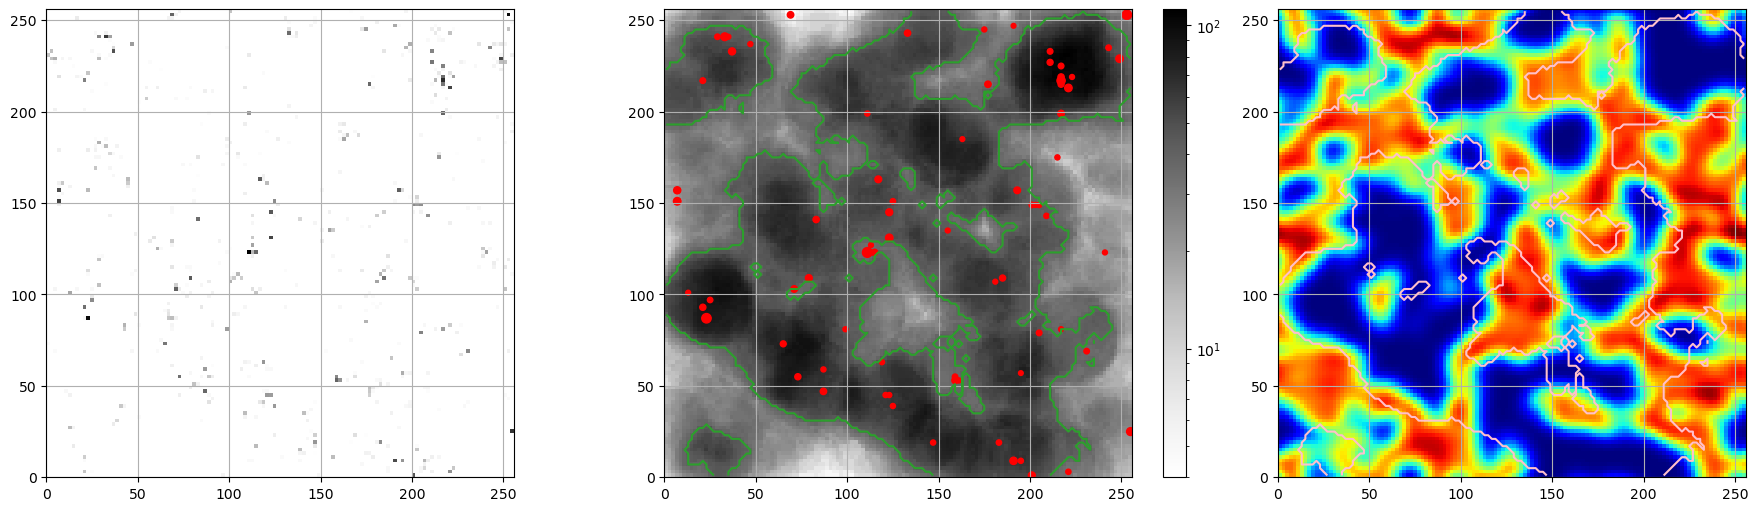

z = 9.868
32.80517009480694


100%|████████████████████████████████████| 10000/10000 [00:49<00:00, 203.46it/s]


<Figure size 640x480 with 0 Axes>

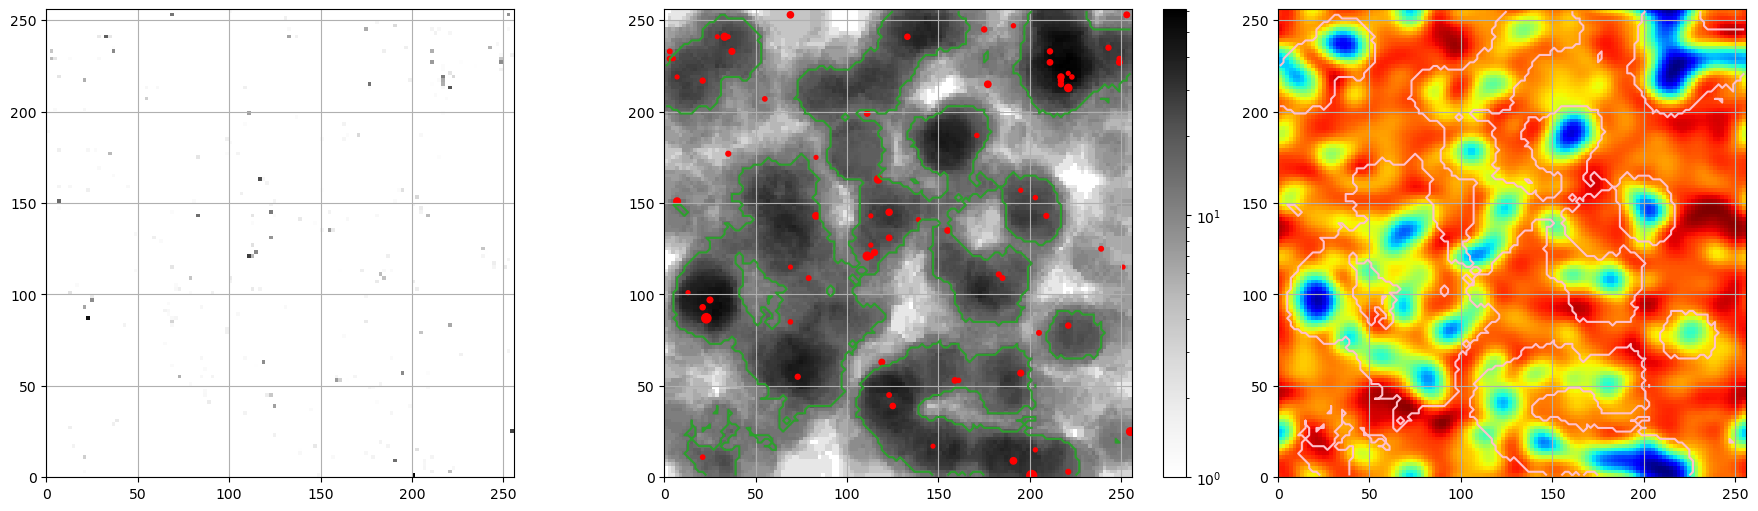

<Figure size 640x480 with 0 Axes>

In [34]:
i_cut = 10000

for z in redshift:
    print('z = %.3f' %z)
    
    nion = np.load('%snion_z%.3f.npy' %(path_input, z))
    dT2 = np.load('%sdT2_z%.3f.npy' %(path_input, z))

    h_pos = np.array(np.nonzero(nion)).T
    src = nion[h_pos[:,0], h_pos[:,1], h_pos[:,2]]

    idx_strongest = src.argsort()[-i_cut:]
    print(idx_strongest.size/h_pos.shape[0]*100)
    src = src[idx_strongest]
    h_pos = h_pos[idx_strongest]

    cube = np.zeros_like(nion)
    for i in tqdm(range(h_pos.shape[0])):
        pos = h_pos[i]
        cube += fake_simulator2(pos=pos, shape=nion.shape, z=z, res=boxsize/nion.shape[0])
    np.save('%ssrcmask2_z%.3f.npy' %(path_out, z), cube)

    # plot
    i_plot = 64
    mask_pos = h_pos[:,2] == i_plot
    
    x_prior = (cube - cube.min())/(cube.max()-cube.min())
    x_prior = x_prior <= x_prior.mean()
    
    fig, axs = plt.subplots(figsize=(18, 5), ncols=3, nrows=1, constrained_layout=True)
    axs[0].imshow(nion[...,i_plot], cmap='Greys', norm='log', origin='lower', extent=[0,256,0,256])
    axs[1].scatter(x=2.*(h_pos[mask_pos, 1]+0.5), y=2.*(h_pos[mask_pos, 0]+0.5), s=src[mask_pos]/src[mask_pos].max()*50, color='red')
    im = axs[1].imshow(cube[...,i_plot], cmap='Greys', origin='lower', extent=[0,256,0,256], norm='log')
    axs[1].contour(x_prior[...,i_plot], levels=[0], origin='lower', extent=[0,256,0,256], colors='tab:green')
    plt.colorbar(im, ax=axs[1])
    axs[2].imshow(dT2[...,i_plot], cmap='jet', origin='lower', extent=[0,256,0,256])
    axs[2].contour(x_prior[...,i_plot], levels=[0], origin='lower', extent=[0,256,0,256], colors='pink')
    
    for ax in axs:
        ax.grid()
    
    plt.show(), plt.clf()

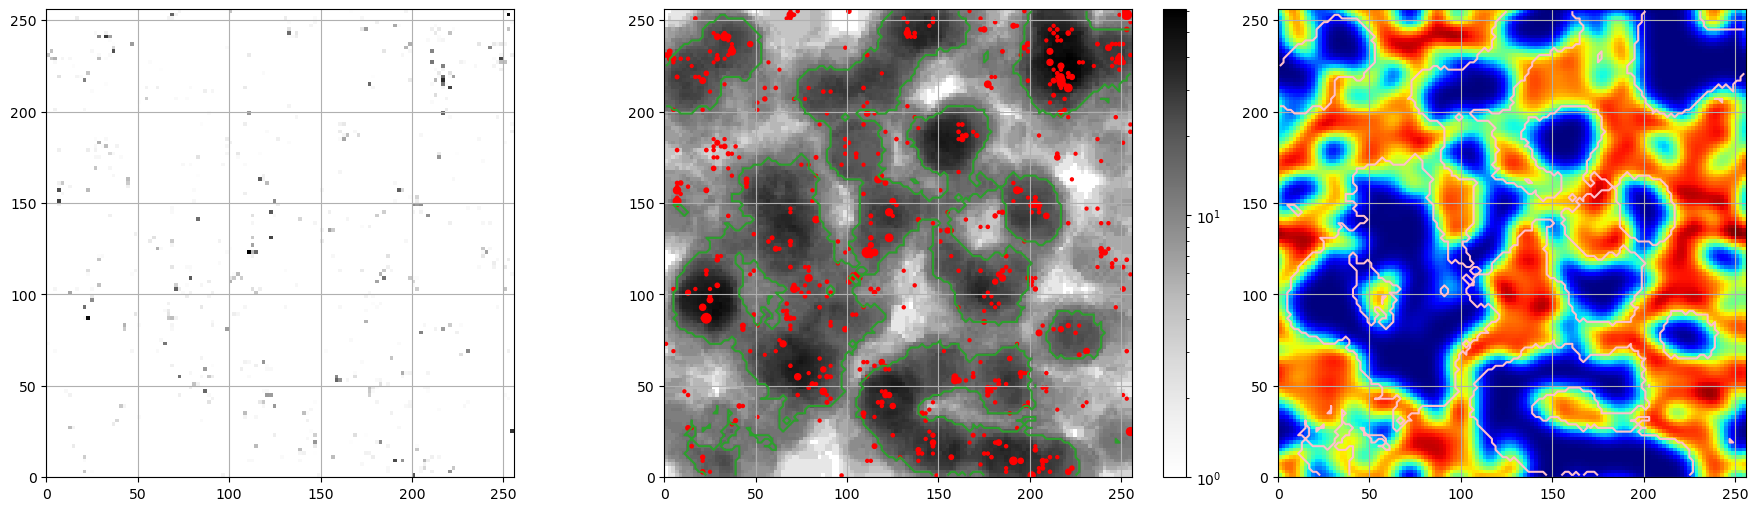

(None, None)

<Figure size 640x480 with 0 Axes>

In [28]:
z = 8.844
dT2 = np.load('%sdT2_z%.3f.npy' %(path_input, z))
nion = np.load('%snion_z%.3f.npy' %(path_input, z))
xHI = np.load('%sxHI_z%.3f.npy' %(path_input, z))
h_pos = np.array(np.nonzero(nion)).T
src = nion[h_pos[:,0], h_pos[:,1], h_pos[:,2]]
cube = np.load('%ssrcmask2_z%.3f.npy' %(path_out,  9.868))

i_plot = 64
mask_pos = h_pos[:,2] == i_plot

x_prior = (cube - cube.min())/(cube.max()-cube.min())
x_prior = x_prior <= x_prior.mean()

fig, axs = plt.subplots(figsize=(18, 5), ncols=3, nrows=1, constrained_layout=True)
axs[0].imshow(nion[...,i_plot], cmap='Greys', norm='log', origin='lower', extent=[0,256,0,256])
axs[1].scatter(x=2.*(h_pos[mask_pos, 1]+0.5), y=2.*(h_pos[mask_pos, 0]+0.5), s=src[mask_pos]/src[mask_pos].max()*50, color='red')
im = axs[1].imshow(cube[...,i_plot], cmap='Greys', origin='lower', extent=[0,256,0,256], norm='log')
axs[1].contour(x_prior[...,i_plot], levels=[0], origin='lower', extent=[0,256,0,256], colors='tab:green')
plt.colorbar(im, ax=axs[1])
axs[2].imshow(dT2[...,i_plot], cmap='jet', origin='lower', extent=[0,256,0,256])
axs[2].contour(x_prior[...,i_plot], levels=[0], origin='lower', extent=[0,256,0,256], colors='pink')

for ax in axs:
    ax.grid()

plt.show(), plt.clf()

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4), ncols=1, nrows=1, constrained_layout=True)
ax.set_title(r'$\bar{x}_{\rm HI}$ = %.1f    z = %.1f' %(mean_xHI, z))
im = ax.imshow(cube[...,i_plot], cmap='Greys', origin='lower', extent=[0,256,0,256], norm='log')
ax.scatter(x=2.*(h_pos[mask_pos, 1]+0.5), y=2.*(h_pos[mask_pos, 0]+0.5), s=10**(src[mask_pos]/src[mask_pos].max()), color='red')
ax.contour(x_prior[...,i_plot], levels=[0], origin='lower', extent=[0,256,0,256], colors='cyan')
ax.contour(example_cube[...,i_plot], levels=[0], origin='lower', extent=[0,256,0,256], colors='lime')

plt.colorbar(im, ax=ax, pad=0.01, fraction=0.048, label='Number Bubble Overlaps')

ax.set_xlabel('x [Mpc]'), ax.set_ylabel('y [Mpc]')
ax.xaxis.set_major_locator(plt.MultipleLocator(50))
ax.xaxis.set_minor_locator(plt.MultipleLocator(25))
ax.yaxis.set_major_locator(plt.MultipleLocator(50))
ax.yaxis.set_minor_locator(plt.MultipleLocator(25))
ax.grid()

#plt.savefig('example_mfp_prior.png' %path_fig, bbox_inches='tight')
plt.show(), plt.clf()

## Plot for the paper

In [5]:
z = 9.868 #8.844

print('z = %.3f' %z)
nion = np.load('%snion_z%.3f.npy' %(path_input, z))
h_pos = np.array(np.nonzero(nion)).T

cube = np.zeros_like(nion)
for i in tqdm(range(h_pos.shape[0])):
    pos = h_pos[i]
    cube += fake_simulator2(pos=pos, shape=nion.shape, z=z, res=2.0)

# make binary prior
x_prior = cube <= cube.mean()

z = 9.868


100%|████████████████████████████████████| 30483/30483 [02:35<00:00, 196.13it/s]


In [6]:
cube.mean()

41.2193

In [7]:
mean_xHI = np.load('%sxHI_z%.3f.npy' %(path_input, z)).mean()
src = nion[h_pos[:,0], h_pos[:,1], h_pos[:,2]]

i_plot = 64
mask_pos = h_pos[:,2] == i_plot

In [51]:
i_example = src[mask_pos].argsort()[-2] # src[mask_pos].argmax()
example_cube = fake_simulator2(pos=h_pos[mask_pos][i_example], shape=nion.shape, z=z, res=boxsize/nion.shape[0])

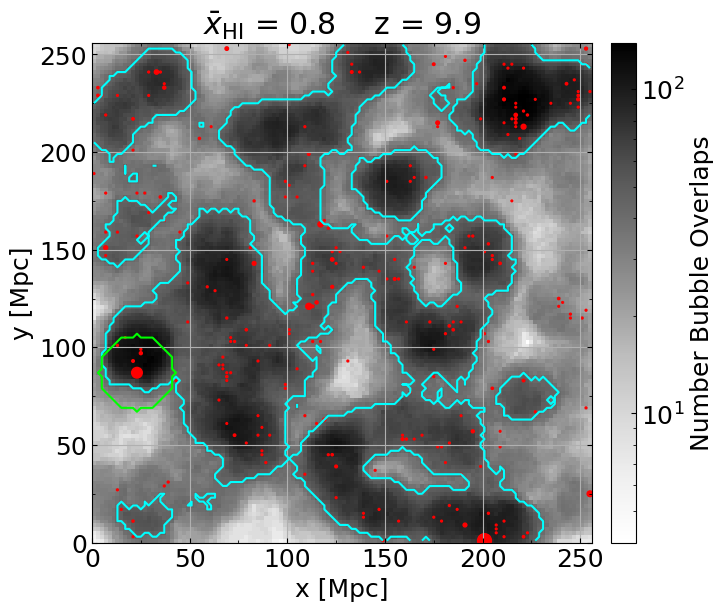

(None, None)

<Figure size 640x480 with 0 Axes>

In [58]:
plt.rcParams['font.size'] = 18
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['xtick.top'] = True
plt.rcParams['ytick.right'] = True

fig, ax = plt.subplots(figsize=(8, 6), ncols=1, nrows=1, constrained_layout=True)
ax.set_title(r'$\bar{x}_{\rm HI}$ = %.1f    z = %.1f' %(mean_xHI, z))
im = ax.imshow(cube[...,i_plot], cmap='Greys', origin='lower', extent=[0,256,0,256], norm='log')
ax.scatter(x=2.*(h_pos[mask_pos, 1]+0.5), y=2.*(h_pos[mask_pos, 0]+0.5), s=100**(src[mask_pos]/src[mask_pos].max()), color='red')
ax.contour(x_prior[...,i_plot], levels=[0], origin='lower', extent=[0,256,0,256], colors='cyan')
ax.contour(example_cube[...,i_plot], levels=[0], origin='lower', extent=[0,256,0,256], colors='lime')

plt.colorbar(im, ax=ax, pad=0.01, fraction=0.048, label='Number Bubble Overlaps')

ax.set_xlabel('x [Mpc]'), ax.set_ylabel('y [Mpc]')
ax.xaxis.set_major_locator(plt.MultipleLocator(50))
ax.xaxis.set_minor_locator(plt.MultipleLocator(25))
ax.yaxis.set_major_locator(plt.MultipleLocator(50))
ax.yaxis.set_minor_locator(plt.MultipleLocator(25))
ax.grid()

#plt.savefig('example_mfp_prior.png', bbox_inches='tight')
plt.show(), plt.clf()